# Results, Robustness and Error Analysis

Summarize the source-to-target performance gap, the repeated few-shot experiment and class-level errors without conducting a new model search. The notebook generates figures and exports analysis tables for a research report or portfolio.

**Inputs:** output artifacts from the preceding notebooks.  
**Outputs:** headline metrics, learning curves, score distributions, confusion matrices, per-class analysis, robustness diagnostics and JSON summaries.

**Interpretation:** reported few-shot statistics are averages across repeated support sets, not the result of a single favourable draw. Aggregate target confusion matrices are reconstructed using the selected episode parameters.

---

## Notebook workflow


## Interpretation policy

evaluation stage is analysis only.

The final method remains the method selected from domain adaptation stage's predefined evaluation procedure. We do **not** change the winner after inspecting particular confusion matrices, box plots, or individual random seeds.

The formal Amsterdam comparison uses the required label budgets:

```text
5, 25, 50, 100, 200 labels per class
```

and reports mean ± SD across repeated support draws.

In [71]:
# Imports and experiment configuration

from pathlib import Path
import json
import pickle
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.svm import SVC

warnings.filterwarnings("ignore")

OFFICIAL_SHOTS = [
    5,
    25,
    50,
    100,
    200,
]

SEED = 42
N_TRIALS = 30

# Confusion matrices for the final target adapter.
# These are small support-set SVM fits, not another model search.
BUILD_TARGET_CONFUSION = True
CONFUSION_SHOTS = [
    25,
    200,
]

KAGGLE_INPUT = Path(
    "/kaggle/input"
)

KAGGLE_WORKING = Path(
    "/kaggle/working"
)

OUTPUT_DIR = (
    KAGGLE_WORKING
    / "track_d"
)

FIGURE_DIR = (
    OUTPUT_DIR
    / "figures"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print(
    "Track D output folder:",
    OUTPUT_DIR,
)

Track D output folder: /kaggle/working/track_d


## 1. Locate feature engineering stage, B and C outputs

Attach the saved outputs of all three earlier notebooks to this notebook.

evaluation stage searches `/kaggle/input` automatically.

In [72]:
def all_candidates(
    filename,
):
    candidates = []

    if KAGGLE_INPUT.exists():
        candidates.extend(
            sorted(
                KAGGLE_INPUT.rglob(
                    filename
                )
            )
        )

    if KAGGLE_WORKING.exists():
        candidates.extend(
            sorted(
                KAGGLE_WORKING.rglob(
                    filename
                )
            )
        )

    candidates.append(
        Path.cwd()
        / filename
    )

    # Remove duplicates while preserving order.
    seen = set()
    unique = []

    for path in candidates:
        if (
            path.exists()
            and str(path)
            not in seen
        ):
            seen.add(
                str(path)
            )
            unique.append(
                path
            )

    return unique


def choose_file(
    filename,
    preferred_token=None,
    required=True,
):
    candidates = all_candidates(
        filename
    )

    if preferred_token:
        preferred = [
            p
            for p in candidates
            if preferred_token.lower()
            in str(p).lower()
        ]

        if preferred:
            return preferred[0]

    if candidates:
        return candidates[0]

    if required:
        raise FileNotFoundError(
            f"Could not find {filename}. "
            "Attach the required Track A/B/C notebook output."
        )

    return None


FEATURES_PATH = choose_file(
    "features.pkl",
    preferred_token="track_a",
)

SOURCE_MODEL_PATH = choose_file(
    "final_model.pkl",
    preferred_token="track_b",
)

TRACK_B_SELECTION_PATH = choose_file(
    "selected_model.json",
    preferred_token="track_b",
    required=False,
)

TRACK_B_CONFIRMATION_PATH = choose_file(
    "confirmation_results.csv",
    preferred_token="track_b",
    required=False,
)

TRACK_B_LOCKBOX_PATH = choose_file(
    "lockbox_result.csv",
    preferred_token="track_b",
    required=False,
)

TRACK_B_CONFUSION_PATH = choose_file(
    "development_confusion.csv",
    preferred_token="track_b",
    required=False,
)

EPISODE_RESULTS_PATH = choose_file(
    "episode_results.csv",
    preferred_token="track_c",
)

PER_CLASS_EPISODE_PATH = choose_file(
    "per_class_episode_results.csv",
    preferred_token="track_c",
)

TRACK_C_SUMMARY_PATH = choose_file(
    "summary.csv",
    preferred_token="track_c",
)

PER_CLASS_SUMMARY_PATH = choose_file(
    "per_class_summary.csv",
    preferred_token="track_c",
)

LEADERBOARD_PATH = choose_file(
    "leaderboard.csv",
    preferred_token="track_c",
)

TRANSFER_SUMMARY_PATH = choose_file(
    "transfer_summary.json",
    preferred_token="track_c",
)

SPATIAL_SUMMARY_PATH = choose_file(
    "spatial_buffer_summary.csv",
    preferred_token="track_c",
    required=False,
)

EPISODES_PATH = choose_file(
    "episodes.pkl",
    preferred_token="track_c",
    required=False,
)

print("Track A:", FEATURES_PATH)
print("Track B:", SOURCE_MODEL_PATH)
print("Track C episodes:", EPISODE_RESULTS_PATH)
print("Track C leaderboard:", LEADERBOARD_PATH)

Track A: /kaggle/working/track_a/features.pkl
Track B: /kaggle/working/track_b/final_model.pkl
Track C episodes: /kaggle/working/track_c/episode_results.csv
Track C leaderboard: /kaggle/working/track_c/leaderboard.csv


## 2. Load the final experiment outputs

In [73]:
with FEATURES_PATH.open(
    "rb"
) as f:
    track_a = pickle.load(
        f
    )

with SOURCE_MODEL_PATH.open(
    "rb"
) as f:
    source_bundle = pickle.load(
        f
    )

episode_results = pd.read_csv(
    EPISODE_RESULTS_PATH
)

per_class_episodes = pd.read_csv(
    PER_CLASS_EPISODE_PATH
)

track_c_summary = pd.read_csv(
    TRACK_C_SUMMARY_PATH
)

per_class_summary = pd.read_csv(
    PER_CLASS_SUMMARY_PATH
)

leaderboard = pd.read_csv(
    LEADERBOARD_PATH
)

with TRANSFER_SUMMARY_PATH.open(
    "r",
    encoding="utf-8",
) as f:
    transfer_summary = json.load(
        f
    )

spatial_summary = (
    pd.read_csv(
        SPATIAL_SUMMARY_PATH
    )
    if (
        SPATIAL_SUMMARY_PATH
        is not None
    )
    else None
)

track_b_confirmation = (
    pd.read_csv(
        TRACK_B_CONFIRMATION_PATH
    )
    if (
        TRACK_B_CONFIRMATION_PATH
        is not None
    )
    else None
)

track_b_lockbox = (
    pd.read_csv(
        TRACK_B_LOCKBOX_PATH
    )
    if (
        TRACK_B_LOCKBOX_PATH
        is not None
    )
    else None
)

print(
    "Episode rows:",
    len(
        episode_results
    ),
)

print(
    "Per-class episode rows:",
    len(
        per_class_episodes
    ),
)

print(
    "Track C methods:",
    sorted(
        episode_results[
            "method"
        ].unique()
    ),
)

Episode rows: 1200
Per-class episode rows: 4800
Track C methods: ['Calibrated source', 'Mean Prototype', 'Median Prototype', 'Shrinkage Prototype', 'Source SVM + HGB', 'Target RBF-SVM', 'Weighted Prototype', 'Zero-shot source']


## 3. Load labels, features and the frozen source model

These are needed only for the confusion matrices and class-balance analysis.

In [74]:
X_amsterdam_raw = np.asarray(
    track_a[
        "X_amsterdam"
    ],
    dtype=np.float32,
)

y_amsterdam_original = np.asarray(
    track_a[
        "y_amsterdam"
    ]
).reshape(-1)

feature_names = list(
    track_a[
        "feature_names"
    ]
)

label_encoder = (
    source_bundle[
        "label_encoder"
    ]
)

y_amsterdam = (
    label_encoder.transform(
        y_amsterdam_original
    )
    .astype(
        np.int64
    )
)

CLASSES = np.arange(
    len(
        label_encoder.classes_
    ),
    dtype=np.int64,
)

source_model = (
    source_bundle[
        "model"
    ]
)

source_imputer = (
    source_bundle[
        "imputer"
    ]
)

source_scaler = (
    source_bundle[
        "scaler"
    ]
)

X_amsterdam = (
    source_scaler.transform(
        source_imputer.transform(
            X_amsterdam_raw
        )
    )
    .astype(
        np.float32
    )
)

print(
    "Amsterdam:",
    X_amsterdam.shape,
)

print(
    "Classes:",
    list(
        label_encoder.classes_
    ),
)

Amsterdam: (25992, 126)
Classes: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


## 4. Final headline results

This table tells the complete story in a few numbers:

1. how well the selected source model performed in Madrid;
2. how far it fell under zero-shot transfer;
3. what 25 labelled pixels per class recovered;
4. what 200 labelled pixels per class achieved.

In [75]:
MADRID_CV = float(
    transfer_summary[
        "madrid_source_cv_macro_f1"
    ]
)

ZERO_SHOT = float(
    transfer_summary[
        "amsterdam_zero_shot_macro_f1"
    ]
)

DOMAIN_DROP = float(
    transfer_summary[
        "source_to_target_drop"
    ]
)

FINAL_METHOD = str(
    transfer_summary[
        "best_average_method"
    ]
)

final_method_summary = (
    track_c_summary[
        (
            track_c_summary[
                "method"
            ]
            == FINAL_METHOD
        )
        & (
            track_c_summary[
                "n_shots"
            ].isin(
                OFFICIAL_SHOTS
            )
        )
    ]
    .sort_values(
        "n_shots"
    )
    .copy()
)

shot25_row = (
    final_method_summary[
        final_method_summary[
            "n_shots"
        ] == 25
    ]
    .iloc[
        0
    ]
)

shot200_row = (
    final_method_summary[
        final_method_summary[
            "n_shots"
        ] == 200
    ]
    .iloc[
        0
    ]
)

F1_25 = float(
    shot25_row[
        "macro_f1_mean"
    ]
)

F1_200 = float(
    shot200_row[
        "macro_f1_mean"
    ]
)

GAIN_25 = (
    F1_25
    - ZERO_SHOT
)

GAIN_200 = (
    F1_200
    - ZERO_SHOT
)

RECOVERED_25 = (
    GAIN_25
    / DOMAIN_DROP
    if DOMAIN_DROP
    > 0
    else np.nan
)

RECOVERED_200 = (
    GAIN_200
    / DOMAIN_DROP
    if DOMAIN_DROP
    > 0
    else np.nan
)

headline = pd.DataFrame([
    {
        "stage": (
            "Madrid source validation"
        ),
        "macro_f1": (
            MADRID_CV
        ),
        "interpretation": (
            "Source-domain reference"
        ),
    },
    {
        "stage": (
            "Amsterdam zero-shot"
        ),
        "macro_f1": (
            ZERO_SHOT
        ),
        "interpretation": (
            "No Amsterdam labels"
        ),
    },
    {
        "stage": (
            "Amsterdam 25-shot"
        ),
        "macro_f1": (
            F1_25
        ),
        "interpretation": (
            FINAL_METHOD
        ),
    },
    {
        "stage": (
            "Amsterdam 200-shot"
        ),
        "macro_f1": (
            F1_200
        ),
        "interpretation": (
            FINAL_METHOD
        ),
    },
])

display(
    headline
)

print(
    "Source → target drop:",
    f"{DOMAIN_DROP:.4f}",
)

print(
    "25-shot gain over zero-shot:",
    f"{GAIN_25:.4f}",
)

print(
    "Fraction of source-target gap recovered at 25-shot:",
    f"{RECOVERED_25:.1%}",
)

print(
    "200-shot gain over zero-shot:",
    f"{GAIN_200:.4f}",
)

print(
    "Fraction of source-target gap recovered at 200-shot:",
    f"{RECOVERED_200:.1%}",
)

headline.to_csv(
    OUTPUT_DIR
    / "headline_results.csv",
    index=False,
)

,stage,macro_f1,interpretation
0,Madrid source validation,0.676815,Source-domain reference
1,Amsterdam zero-shot,0.394313,No Amsterdam labels
2,Amsterdam 25-shot,0.595044,Target RBF-SVM
3,Amsterdam 200-shot,0.699773,Target RBF-SVM


Source → target drop: 0.2825
25-shot gain over zero-shot: 0.2007
Fraction of source-target gap recovered at 25-shot: 71.1%
200-shot gain over zero-shot: 0.3055
Fraction of source-target gap recovered at 200-shot: 108.1%


## 5. model selection stage — source-model evidence

Where the model-selection files are available, this section shows the full confirmation-stage candidates and the independent Madrid lockbox score.

This is useful for demonstrating that the source model was selected before Amsterdam adaptation.

In [76]:
if (
    track_b_confirmation
    is not None
):
    display(
        track_b_confirmation
        .sort_values(
            "mean_macro_f1",
            ascending=False,
        )
    )

else:
    print(
        "Track-B confirmation_results.csv was not attached."
    )

if (
    track_b_lockbox
    is not None
):
    print(
        "\nTrack-B lockbox:"
    )

    display(
        track_b_lockbox
    )

,stage,configuration,model,params,mean_macro_f1,sd_macro_f1,min_macro_f1,max_macro_f1,seconds,status,artifact_fingerprint
0,confirmation,RBF SVM C10,RBF SVM,{'C': 10.0},0.676815,0.002176,0.673341,0.679971,2133.941282,OK,d9e7555cf767324a13e0
1,confirmation,RBF SVM C2,RBF SVM,{'C': 2.0},0.661621,0.002583,0.659294,0.666258,2156.339486,OK,d9e7555cf767324a13e0
2,confirmation,LightGBM,LightGBM,"{'n_estimators': 500, 'learning_rate': 0.06, '...",0.659026,0.004849,0.653001,0.667489,122.007393,OK,d9e7555cf767324a13e0
3,confirmation,HistGradientBoosting B,HistGradientBoosting,"{'learning_rate': 0.07, 'max_iter': 350, 'max_...",0.658382,0.003650,0.651547,0.662563,111.255689,OK,d9e7555cf767324a13e0
4,confirmation,XGBoost,XGBoost,"{'n_estimators': 500, 'max_depth': 5, 'learnin...",0.654527,0.004089,0.649572,0.661360,156.482152,OK,d9e7555cf767324a13e0



Track-B lockbox:


,configuration,model,confirmation_mean_macro_f1,confirmation_sd_macro_f1,lockbox_macro_f1
0,RBF SVM C10,RBF SVM,0.676815,0.002176,0.675759


## 6. domain adaptation stage — complete method leaderboard

In [77]:
display(
    leaderboard
)

leaderboard.to_csv(
    OUTPUT_DIR
    / "final_leaderboard.csv",
    index=False,
)

,method,average_f1,average_sd,peak_mean_f1,average_spatial_f1,f1_25,sd_25,spatial_f1_25
0,Target RBF-SVM,0.609838,0.022239,0.699773,0.600705,0.595044,0.024285,0.590326
1,Median Prototype,0.463920,0.030186,0.488094,0.458862,0.463414,0.036952,0.461467
2,Source SVM + HGB,0.457517,0.000257,0.458267,0.452846,0.458073,0.000178,0.456493
3,Calibrated source,0.397235,0.021762,0.408411,0.392242,0.393863,0.030313,0.391820
4,Shrinkage Prototype,0.287146,0.037116,0.344106,0.283543,0.311873,0.036960,0.310493
5,Weighted Prototype,0.258258,0.054910,0.298787,0.254453,0.274510,0.063459,0.272739
6,Mean Prototype,0.239907,0.054491,0.283589,0.236336,0.255751,0.062363,0.254031


## 7. Official final-method table

This is the main Amsterdam table for the report/presentation.

In [78]:
final_results = (
    final_method_summary[
        [
            "n_shots",
            "macro_f1_mean",
            "macro_f1_std",
            "spatial_macro_f1_mean",
            "spatial_macro_f1_std",
        ]
    ]
    .rename(
        columns={
            "n_shots": (
                "labels_per_class"
            ),
            "macro_f1_mean": (
                "macro_f1_mean"
            ),
            "macro_f1_std": (
                "macro_f1_sd"
            ),
            "spatial_macro_f1_mean": (
                "spatial_macro_f1_mean"
            ),
            "spatial_macro_f1_std": (
                "spatial_macro_f1_sd"
            ),
        }
    )
)

display(
    final_results
)

final_results.to_csv(
    OUTPUT_DIR
    / "final_results_table.csv",
    index=False,
)

,labels_per_class,macro_f1_mean,macro_f1_sd,spatial_macro_f1_mean,spatial_macro_f1_sd
1,5,0.448071,0.052321,0.446554,0.052284
8,25,0.595044,0.024285,0.590326,0.024513
16,50,0.638500,0.014920,0.630592,0.015441
24,100,0.667805,0.011554,0.655256,0.013000
32,200,0.699773,0.008114,0.680797,0.009606


## 8. Amsterdam class distribution

The target classes are imbalanced, which is why Macro-F1 is the correct headline metric.

,class,count,proportion
0,1,7568,0.291167
1,2,8802,0.338643
2,3,6745,0.259503
3,4,2877,0.110688


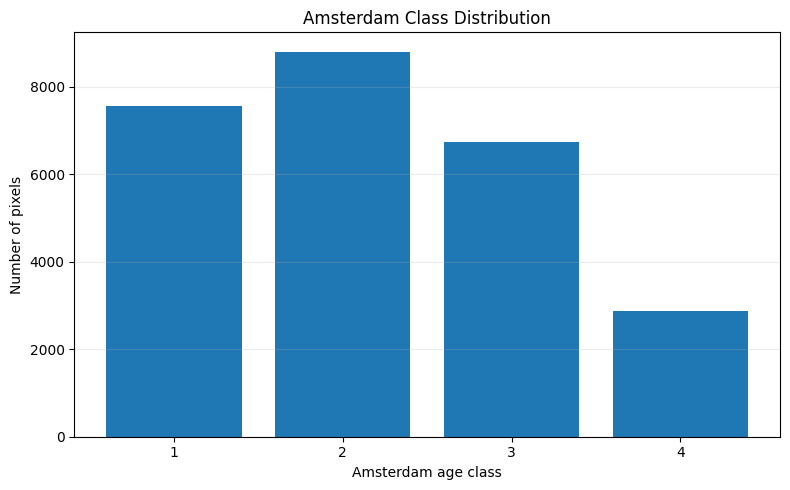

In [79]:
class_counts = (
    pd.Series(
        y_amsterdam_original
    )
    .value_counts()
    .sort_index()
)

class_distribution = (
    pd.DataFrame({
        "class": (
            class_counts.index
        ),
        "count": (
            class_counts.values
        ),
        "proportion": (
            class_counts.values
            / class_counts.values.sum()
        ),
    })
)

display(
    class_distribution
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.bar(
    class_distribution[
        "class"
    ].astype(
        str
    ),
    class_distribution[
        "count"
    ],
)

ax.set_xlabel(
    "Amsterdam age class"
)

ax.set_ylabel(
    "Number of pixels"
)

ax.set_title(
    "Amsterdam Class Distribution"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "amsterdam_class_distribution.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 9. Domain shift and adaptation recovery

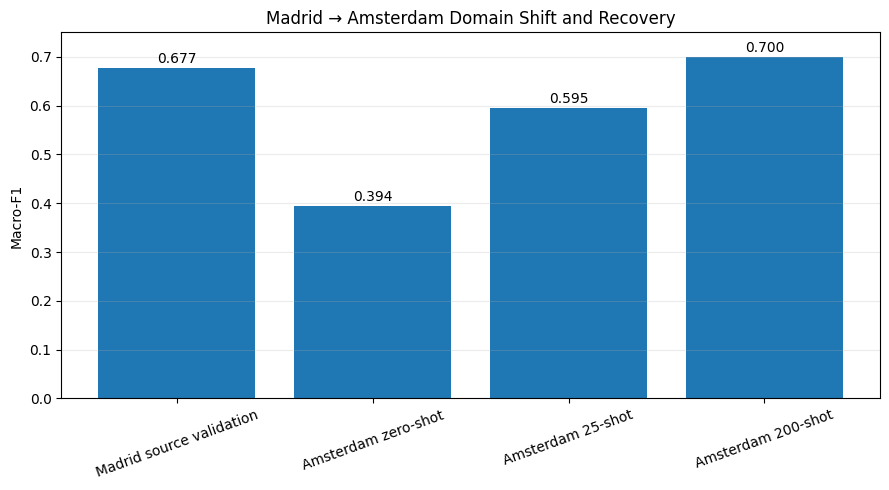

In [80]:
fig, ax = plt.subplots(
    figsize=(9, 5)
)

ax.bar(
    headline[
        "stage"
    ],
    headline[
        "macro_f1"
    ],
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Madrid → Amsterdam Domain Shift and Recovery"
)

ax.set_ylim(
    0,
    max(
        0.75,
        headline[
            "macro_f1"
        ].max()
        + 0.05,
    ),
)

ax.tick_params(
    axis="x",
    rotation=20,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

for i, value in enumerate(
    headline[
        "macro_f1"
    ]
):
    ax.text(
        i,
        value
        + 0.01,
        f"{value:.3f}",
        ha="center",
    )

plt.tight_layout()

path = (
    FIGURE_DIR
    / "domain_shift_and_recovery.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 10. F1 versus labelled pixels per class

Mean ± SD over repeated support draws.

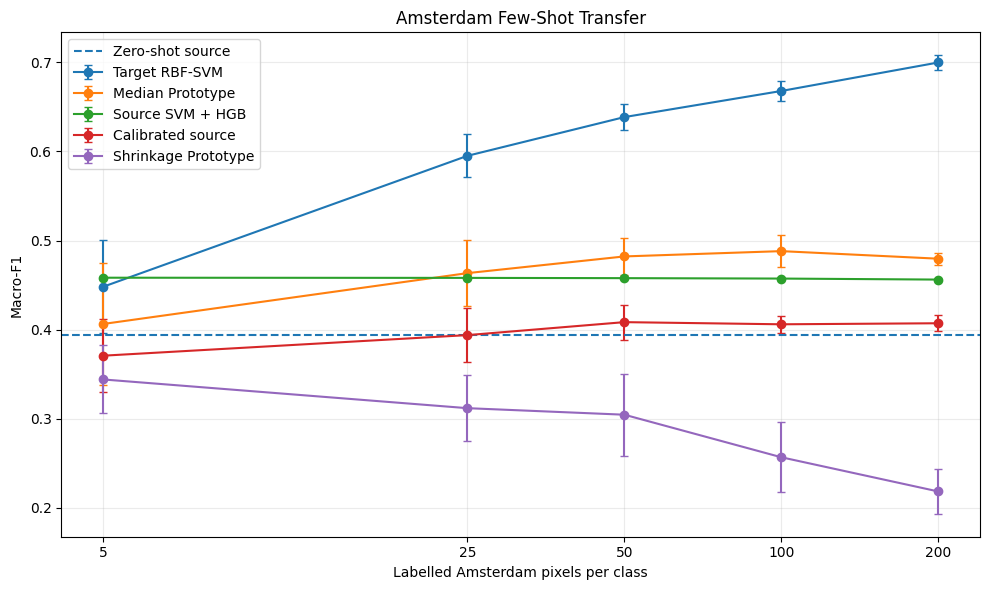

In [81]:
methods_to_plot = [
    "Target RBF-SVM",
    "Median Prototype",
    "Source SVM + HGB",
    "Calibrated source",
    "Shrinkage Prototype",
]

available_methods = set(
    track_c_summary[
        "method"
    ]
)

methods_to_plot = [
    method
    for method
    in methods_to_plot
    if method
    in available_methods
]

fig, ax = plt.subplots(
    figsize=(10, 6)
)

for method in (
    methods_to_plot
):
    part = (
        track_c_summary[
            (
                track_c_summary[
                    "method"
                ]
                == method
            )
            & (
                track_c_summary[
                    "n_shots"
                ].isin(
                    OFFICIAL_SHOTS
                )
            )
        ]
        .sort_values(
            "n_shots"
        )
    )

    ax.errorbar(
        part[
            "n_shots"
        ],
        part[
            "macro_f1_mean"
        ],
        yerr=part[
            "macro_f1_std"
        ],
        marker="o",
        capsize=3,
        label=method,
    )

ax.axhline(
    ZERO_SHOT,
    linestyle="--",
    label="Zero-shot source",
)

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    OFFICIAL_SHOTS
)

ax.set_xticklabels(
    [
        str(x)
        for x
        in OFFICIAL_SHOTS
    ]
)

ax.set_xlabel(
    "Labelled Amsterdam pixels per class"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Amsterdam Few-Shot Transfer"
)

ax.grid(
    alpha=0.25,
)

ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "f1_vs_shots.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 11. 25-shot box plot

A box plot reveals information hidden by mean ± SD:

- median;
- interquartile range;
- outlying easy/hard support draws;
- how much the low-shot methods overlap.

This uses the exact repeated episodes from domain adaptation stage.

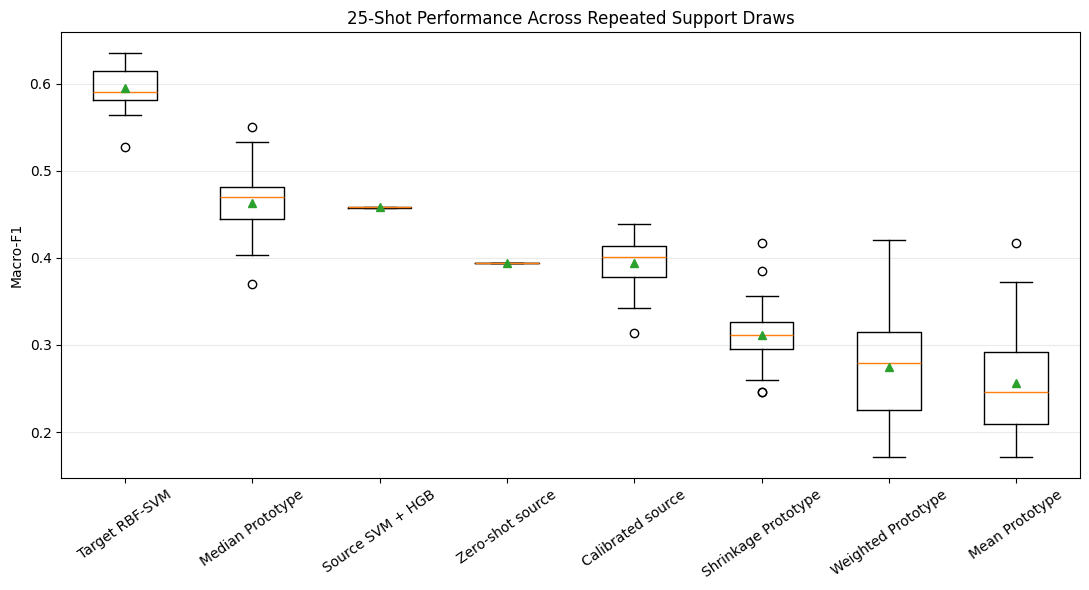

In [82]:
shot25 = (
    episode_results[
        episode_results[
            "n_shots"
        ]
        == 25
    ]
    .copy()
)

method_order = (
    shot25
    .groupby(
        "method"
    )[
        "macro_f1"
    ]
    .mean()
    .sort_values(
        ascending=False
    )
    .index
    .tolist()
)

box_data = [
    shot25.loc[
        shot25[
            "method"
        ]
        == method,
        "macro_f1",
    ].to_numpy()
    for method
    in method_order
]

fig, ax = plt.subplots(
    figsize=(11, 6)
)

ax.boxplot(
    box_data,
    labels=method_order,
    showmeans=True,
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "25-Shot Performance Across Repeated Support Draws"
)

ax.tick_params(
    axis="x",
    rotation=35,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "boxplot_25_shot.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 12. Final-method box plot across all shot sizes

This makes the improvement in both performance and stability visible as more Amsterdam labels become available.

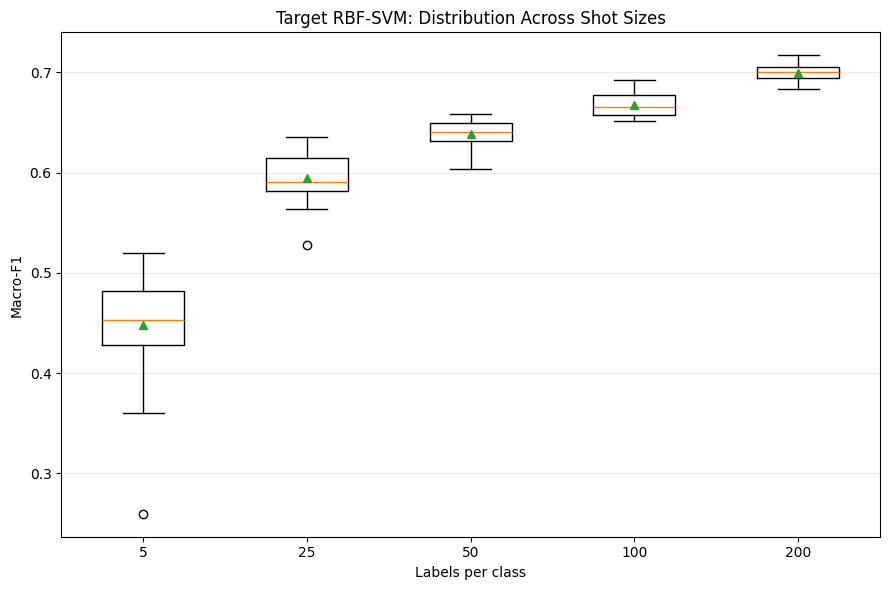

In [83]:
final_episode_rows = (
    episode_results[
        (
            episode_results[
                "method"
            ]
            == FINAL_METHOD
        )
        & (
            episode_results[
                "n_shots"
            ].isin(
                OFFICIAL_SHOTS
            )
        )
    ]
    .copy()
)

box_data = [
    final_episode_rows.loc[
        final_episode_rows[
            "n_shots"
        ]
        == shot,
        "macro_f1",
    ].to_numpy()
    for shot
    in OFFICIAL_SHOTS
]

fig, ax = plt.subplots(
    figsize=(9, 6)
)

ax.boxplot(
    box_data,
    labels=[
        str(
            shot
        )
        for shot
        in OFFICIAL_SHOTS
    ],
    showmeans=True,
)

ax.set_xlabel(
    "Labels per class"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    f"{FINAL_METHOD}: Distribution Across Shot Sizes"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "final_method_boxplot_by_shot.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 13. 25-shot histogram for the final method

The histogram shows the actual distribution behind the 25-shot mean ± SD.

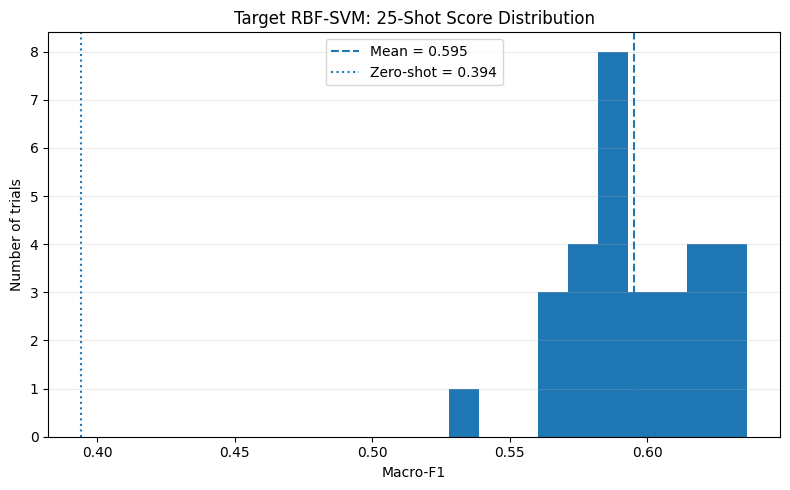

In [84]:
final_25_scores = (
    final_episode_rows.loc[
        final_episode_rows[
            "n_shots"
        ]
        == 25,
        "macro_f1",
    ]
    .to_numpy()
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.hist(
    final_25_scores,
    bins=10,
)

ax.axvline(
    final_25_scores.mean(),
    linestyle="--",
    label=(
        f"Mean = "
        f"{final_25_scores.mean():.3f}"
    ),
)

ax.axvline(
    ZERO_SHOT,
    linestyle=":",
    label=(
        f"Zero-shot = "
        f"{ZERO_SHOT:.3f}"
    ),
)

ax.set_xlabel(
    "Macro-F1"
)

ax.set_ylabel(
    "Number of trials"
)

ax.set_title(
    f"{FINAL_METHOD}: 25-Shot Score Distribution"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "histogram_final_method_25_shot.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 14. Per-class performance for the final method

This prevents a high Macro-F1 from hiding one consistently weak age class.

,method,n_shots,class,f1_mean,f1_std,f1_count,spatial_f1_mean,spatial_f1_std,spatial_f1_count
100,Target RBF-SVM,5,1,0.577281,0.075941,30,0.576318,0.075943,30
101,Target RBF-SVM,5,2,0.423135,0.105490,30,0.422367,0.105784,30
102,Target RBF-SVM,5,3,0.445517,0.073662,30,0.444178,0.073781,30
103,Target RBF-SVM,5,4,0.346350,0.081529,30,0.343354,0.081725,30
104,Target RBF-SVM,25,1,0.671322,0.031859,30,0.668030,0.031630,30
105,Target RBF-SVM,25,2,0.561993,0.040852,30,0.560463,0.040867,30
106,Target RBF-SVM,25,3,0.596538,0.042901,30,0.592905,0.043514,30
107,Target RBF-SVM,25,4,0.550324,0.038850,30,0.539904,0.039365,30
108,Target RBF-SVM,50,1,0.695484,0.018924,30,0.690195,0.018898,30
109,Target RBF-SVM,50,2,0.607890,0.021279,30,0.605519,0.021707,30


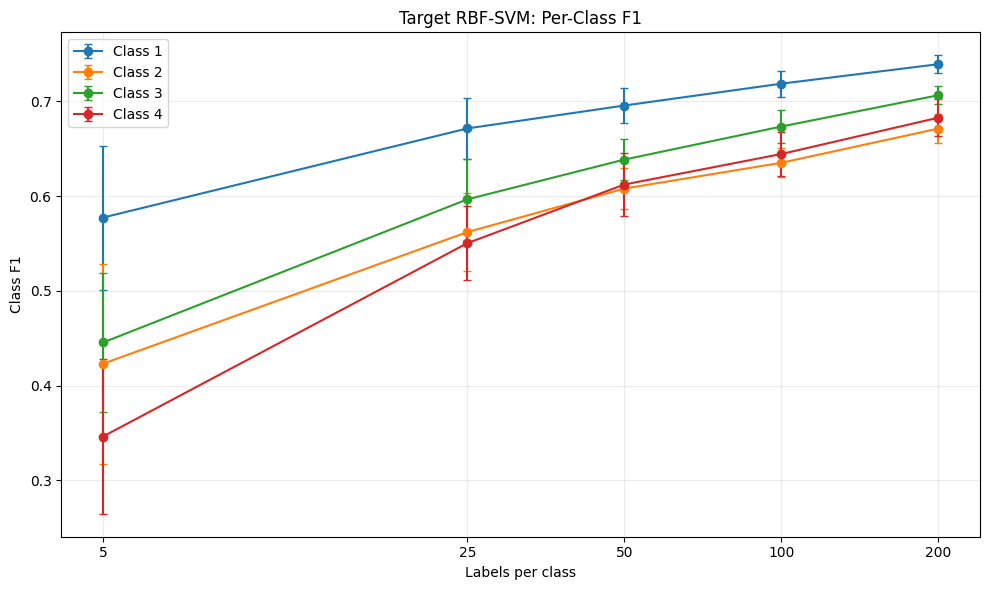

In [85]:
final_per_class = (
    per_class_summary[
        (
            per_class_summary[
                "method"
            ]
            == FINAL_METHOD
        )
        & (
            per_class_summary[
                "n_shots"
            ].isin(
                OFFICIAL_SHOTS
            )
        )
    ]
    .copy()
)

display(
    final_per_class
)

final_per_class.to_csv(
    OUTPUT_DIR
    / "final_per_class_results.csv",
    index=False,
)

fig, ax = plt.subplots(
    figsize=(10, 6)
)

for class_label in sorted(
    final_per_class[
        "class"
    ].unique()
):
    part = (
        final_per_class[
            final_per_class[
                "class"
            ]
            == class_label
        ]
        .sort_values(
            "n_shots"
        )
    )

    ax.errorbar(
        part[
            "n_shots"
        ],
        part[
            "f1_mean"
        ],
        yerr=part[
            "f1_std"
        ],
        marker="o",
        capsize=3,
        label=(
            f"Class {class_label}"
        ),
    )

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    OFFICIAL_SHOTS
)

ax.set_xticklabels(
    [
        str(x)
        for x
        in OFFICIAL_SHOTS
    ]
)

ax.set_xlabel(
    "Labels per class"
)

ax.set_ylabel(
    "Class F1"
)

ax.set_title(
    f"{FINAL_METHOD}: Per-Class F1"
)

ax.grid(
    alpha=0.25,
)

ax.legend()

plt.tight_layout()

path = (
    FIGURE_DIR
    / "final_method_per_class_f1.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 15. Spatial-buffer diagnostic

domain adaptation stage also evaluated query pixels after excluding those close to the support set.

If the buffered score stays close to the ordinary score, that is evidence that the result is not being driven entirely by immediately neighbouring pixels.

,method,n_shots,macro_f1_mean,macro_f1_std,spatial_macro_f1_mean,spatial_macro_f1_std,spatial_macro_f1_count,spatial_drop
1,Target RBF-SVM,5,0.448071,0.052321,0.446554,0.052284,30,0.001516
8,Target RBF-SVM,25,0.595044,0.024285,0.590326,0.024513,30,0.004719
16,Target RBF-SVM,50,0.638500,0.014920,0.630592,0.015441,30,0.007907
24,Target RBF-SVM,100,0.667805,0.011554,0.655256,0.013000,30,0.012548
32,Target RBF-SVM,200,0.699773,0.008114,0.680797,0.009606,30,0.018976


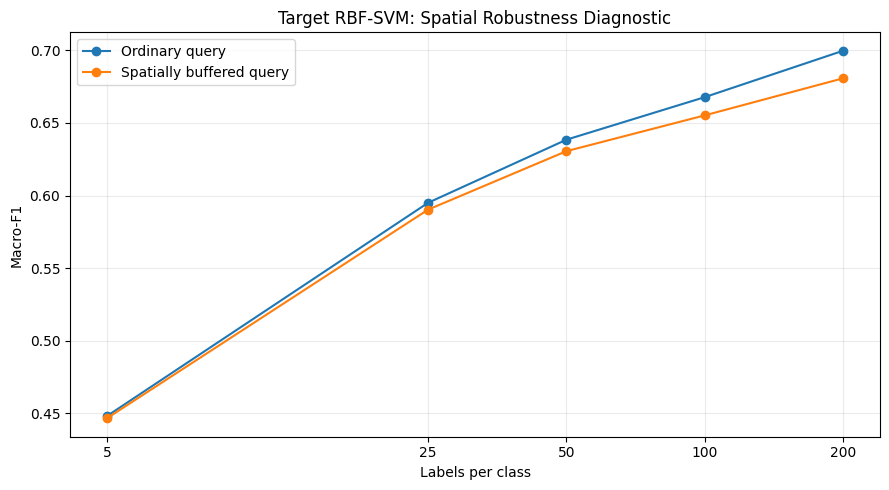

In [86]:
if (
    spatial_summary
    is not None
):
    final_spatial = (
        spatial_summary[
            (
                spatial_summary[
                    "method"
                ]
                == FINAL_METHOD
            )
            & (
                spatial_summary[
                    "n_shots"
                ].isin(
                    OFFICIAL_SHOTS
                )
            )
        ]
        .sort_values(
            "n_shots"
        )
        .copy()
    )

    display(
        final_spatial
    )

    fig, ax = plt.subplots(
        figsize=(9, 5)
    )

    ax.plot(
        final_spatial[
            "n_shots"
        ],
        final_spatial[
            "macro_f1_mean"
        ],
        marker="o",
        label=(
            "Ordinary query"
        ),
    )

    ax.plot(
        final_spatial[
            "n_shots"
        ],
        final_spatial[
            "spatial_macro_f1_mean"
        ],
        marker="o",
        label=(
            "Spatially buffered query"
        ),
    )

    ax.set_xscale(
        "log",
        base=2,
    )

    ax.set_xticks(
        OFFICIAL_SHOTS
    )

    ax.set_xticklabels(
        [
            str(x)
            for x
            in OFFICIAL_SHOTS
        ]
    )

    ax.set_xlabel(
        "Labels per class"
    )

    ax.set_ylabel(
        "Macro-F1"
    )

    ax.set_title(
        f"{FINAL_METHOD}: Spatial Robustness Diagnostic"
    )

    ax.grid(
        alpha=0.25,
    )

    ax.legend()

    plt.tight_layout()

    path = (
        FIGURE_DIR
        / "spatial_buffer_comparison.png"
    )

    plt.savefig(
        path,
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

else:
    print(
        "No spatial_buffer_summary.csv was attached."
    )

## 16. Zero-shot confusion matrix

Rows are true Amsterdam classes; columns are predicted classes.

The normalized matrix makes each row interpretable as class recall / confusion proportions.

,Pred 1,Pred 2,Pred 3,Pred 4
True 1,0.670058,0.108747,0.009646,0.211549
True 2,0.334356,0.290729,0.042377,0.332538
True 3,0.105263,0.272053,0.165456,0.457228
True 4,0.063956,0.144595,0.039277,0.752172


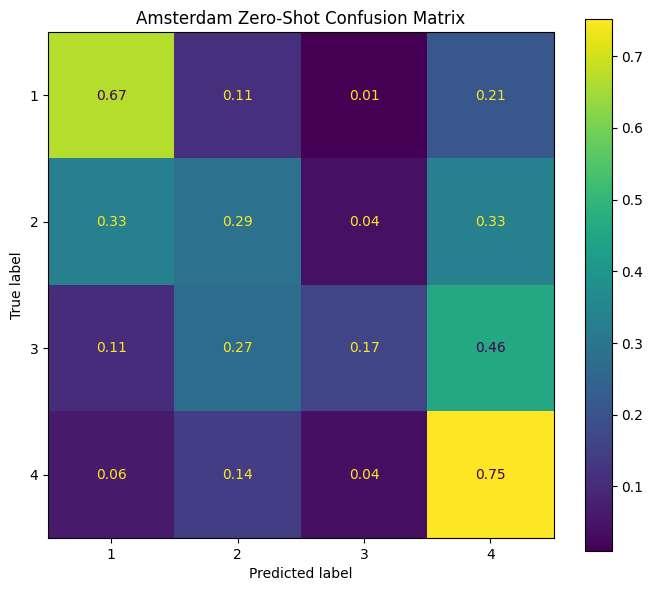

In [87]:
zero_shot_pred = np.asarray(
    source_model.predict(
        X_amsterdam
    )
).reshape(-1).astype(
    np.int64
)

zero_cm = confusion_matrix(
    y_amsterdam,
    zero_shot_pred,
    labels=CLASSES,
    normalize="true",
)

zero_cm_df = pd.DataFrame(
    zero_cm,
    index=[
        f"True {c}"
        for c
        in label_encoder.classes_
    ],
    columns=[
        f"Pred {c}"
        for c
        in label_encoder.classes_
    ],
)

display(
    zero_cm_df
)

zero_cm_df.to_csv(
    OUTPUT_DIR
    / "zero_shot_confusion_matrix.csv"
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=zero_cm,
    display_labels=(
        label_encoder.classes_
    ),
)

disp.plot(
    ax=ax,
    values_format=".2f",
)

ax.set_title(
    "Amsterdam Zero-Shot Confusion Matrix"
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "zero_shot_confusion_matrix.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 17. Recover the domain-adaptation episodes

If `episodes.pkl` is available, evaluation stage uses it.

Otherwise the exact random-balanced episode generator from domain adaptation stage is reconstructed with the same seed convention.

In [88]:
def rebuild_episodes():
    rebuilt = {}

    for n_shots in (
        OFFICIAL_SHOTS
    ):
        rebuilt[
            n_shots
        ] = []

        for trial in range(
            N_TRIALS
        ):
            rng = (
                np.random.default_rng(
                    SEED
                    + 10_000
                    * n_shots
                    + trial
                )
            )

            support_parts = []

            for cls in CLASSES:
                cls_idx = (
                    np.flatnonzero(
                        y_amsterdam
                        == cls
                    )
                )

                chosen = rng.choice(
                    cls_idx,
                    size=n_shots,
                    replace=False,
                )

                support_parts.append(
                    chosen
                )

            support_idx = (
                np.concatenate(
                    support_parts
                )
                .astype(
                    np.int32
                )
            )

            rng.shuffle(
                support_idx
            )

            query_mask = (
                np.ones(
                    len(
                        y_amsterdam
                    ),
                    dtype=bool,
                )
            )

            query_mask[
                support_idx
            ] = False

            query_idx = (
                np.flatnonzero(
                    query_mask
                )
                .astype(
                    np.int32
                )
            )

            rebuilt[
                n_shots
            ].append({
                "trial": (
                    trial
                ),
                "support_idx": (
                    support_idx
                ),
                "query_idx": (
                    query_idx
                ),
            })

    return rebuilt


if (
    EPISODES_PATH
    is not None
):
    with EPISODES_PATH.open(
        "rb"
    ) as f:
        episodes = pickle.load(
            f
        )

    print(
        "Loaded Track-C episodes."
    )

else:
    support_sampling = (
        transfer_summary.get(
            "support_sampling",
            "random_balanced",
        )
    )

    if (
        support_sampling
        != "random_balanced"
    ):
        raise RuntimeError(
            "episodes.pkl is required because Track C did not use "
            "ordinary random-balanced support sampling."
        )

    episodes = (
        rebuild_episodes()
    )

    print(
        "Rebuilt Track-C random-balanced episodes."
    )

Loaded Track-C episodes.


## 18. Aggregate confusion matrix for the final Target RBF-SVM

A single trial can be misleading.

For each requested shot size, this section:

1. recreates the Target RBF-SVM using the **C and gamma already selected in domain adaptation stage for that episode**;
2. predicts that episode's query set;
3. computes a row-normalized confusion matrix;
4. averages the matrices across all 30 episodes.

No new tuning is performed.

By default we create matrices for:

- **25-shot** — the key low-data setting;
- **200-shot** — the peak-performance setting.

In [89]:
def parse_gamma(
    value,
):
    text = str(
        value
    )

    if text in {
        "scale",
        "auto",
    }:
        return text

    return float(
        text
    )


def aggregate_target_svm_confusion(
    n_shots,
):
    matrices = []
    check_scores = []

    shot_rows = (
        episode_results[
            (
                episode_results[
                    "method"
                ]
                == "Target RBF-SVM"
            )
            & (
                episode_results[
                    "n_shots"
                ]
                == n_shots
            )
        ]
        .sort_values(
            "trial"
        )
        .copy()
    )

    if (
        len(
            shot_rows
        )
        != N_TRIALS
    ):
        raise ValueError(
            f"Expected {N_TRIALS} Target RBF-SVM rows "
            f"for {n_shots}-shot; found {len(shot_rows)}."
        )

    for row in (
        shot_rows.itertuples()
    ):
        trial = int(
            row.trial
        )

        episode = (
            episodes[
                n_shots
            ][
                trial
            ]
        )

        support_idx = episode[
            "support_idx"
        ]

        query_idx = episode[
            "query_idx"
        ]

        C = float(
            row.selected_C
        )

        gamma = parse_gamma(
            row.selected_gamma
        )

        model = SVC(
            C=C,
            gamma=gamma,
            kernel="rbf",
            class_weight="balanced",
            probability=False,
            cache_size=1024,
        )

        model.fit(
            X_amsterdam[
                support_idx
            ],
            y_amsterdam[
                support_idx
            ],
        )

        pred = np.asarray(
            model.predict(
                X_amsterdam[
                    query_idx
                ]
            )
        ).reshape(-1).astype(
            np.int64
        )

        score = f1_score(
            y_amsterdam[
                query_idx
            ],
            pred,
            labels=CLASSES,
            average="macro",
            zero_division=0,
        )

        check_scores.append(
            score
        )

        matrices.append(
            confusion_matrix(
                y_amsterdam[
                    query_idx
                ],
                pred,
                labels=CLASSES,
                normalize="true",
            )
        )

    mean_cm = np.mean(
        matrices,
        axis=0,
    )

    return (
        mean_cm,
        np.asarray(
            check_scores
        ),
    )

25-shot reconstructed mean F1: 0.595044
25-shot saved Track-C mean F1: 0.595044


,Pred 1,Pred 2,Pred 3,Pred 4
True 1,0.722471,0.184820,0.058323,0.034385
True 2,0.268349,0.528377,0.126174,0.077099
True 3,0.107262,0.185079,0.551121,0.156538
True 4,0.061583,0.142871,0.154535,0.641012


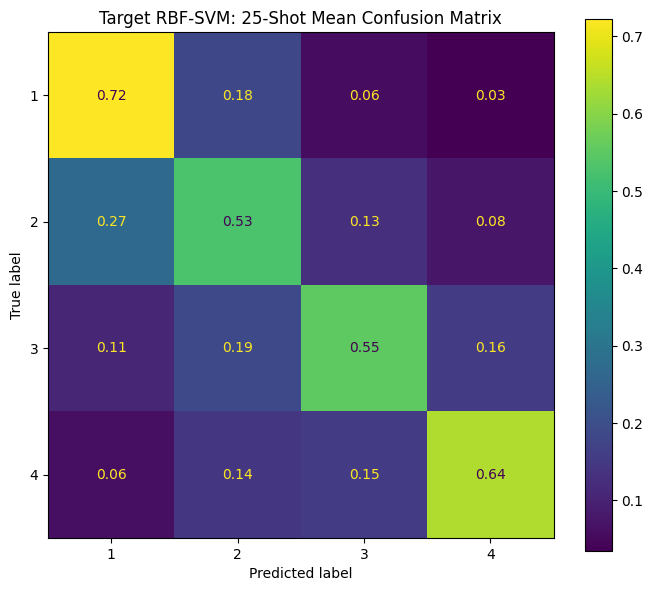

200-shot reconstructed mean F1: 0.699773
200-shot saved Track-C mean F1: 0.699773


,Pred 1,Pred 2,Pred 3,Pred 4
True 1,0.777959,0.156279,0.041499,0.024263
True 2,0.205863,0.649860,0.090777,0.053499
True 3,0.083967,0.158279,0.658355,0.099399
True 4,0.034579,0.101793,0.097286,0.766343


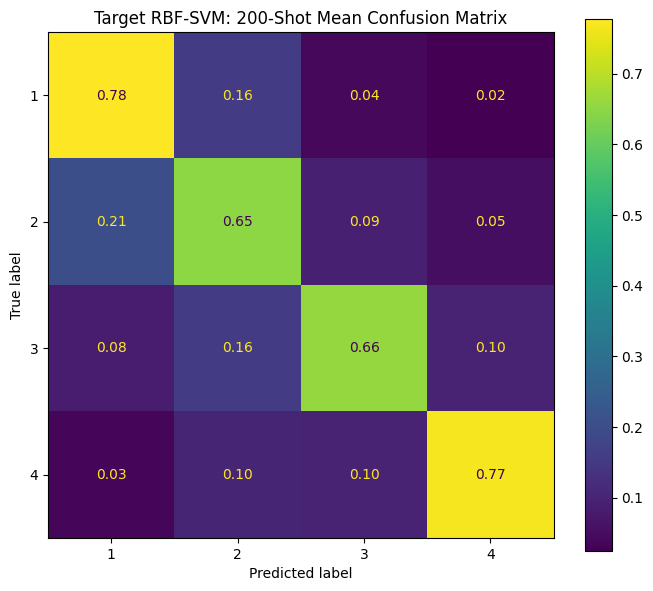

In [90]:
if (
    BUILD_TARGET_CONFUSION
    and FINAL_METHOD
    == "Target RBF-SVM"
):
    for shot in (
        CONFUSION_SHOTS
    ):
        (
            mean_cm,
            check_scores,
        ) = (
            aggregate_target_svm_confusion(
                shot
            )
        )

        expected_mean = float(
            final_method_summary.loc[
                final_method_summary[
                    "n_shots"
                ]
                == shot,
                "macro_f1_mean",
            ].iloc[
                0
            ]
        )

        print(
            f"{shot}-shot reconstructed mean F1:",
            f"{check_scores.mean():.6f}",
        )

        print(
            f"{shot}-shot saved Track-C mean F1:",
            f"{expected_mean:.6f}",
        )

        cm_df = pd.DataFrame(
            mean_cm,
            index=[
                f"True {c}"
                for c
                in label_encoder.classes_
            ],
            columns=[
                f"Pred {c}"
                for c
                in label_encoder.classes_
            ],
        )

        display(
            cm_df
        )

        cm_df.to_csv(
            OUTPUT_DIR
            / (
                f"target_svm_"
                f"{shot}_shot_"
                f"confusion_matrix.csv"
            )
        )

        fig, ax = plt.subplots(
            figsize=(7, 6)
        )

        disp = (
            ConfusionMatrixDisplay(
                confusion_matrix=(
                    mean_cm
                ),
                display_labels=(
                    label_encoder.classes_
                ),
            )
        )

        disp.plot(
            ax=ax,
            values_format=".2f",
        )

        ax.set_title(
            f"Target RBF-SVM: "
            f"{shot}-Shot Mean Confusion Matrix"
        )

        plt.tight_layout()

        path = (
            FIGURE_DIR
            / (
                f"target_svm_"
                f"{shot}_shot_"
                f"confusion_matrix.png"
            )
        )

        plt.savefig(
            path,
            dpi=180,
            bbox_inches="tight",
        )

        plt.show()

else:
    print(
        "Aggregate Target RBF-SVM confusion matrices skipped."
    )

## 19. Stability analysis

For the final method, the SD should generally decrease as more labels become available.

This table also reports the coefficient of variation:

```text
CV = SD / mean
```

as a simple relative-stability indicator.

,n_shots,macro_f1_mean,macro_f1_std,coefficient_of_variation
1,5,0.448071,0.052321,0.116769
8,25,0.595044,0.024285,0.040812
16,50,0.638500,0.014920,0.023367
24,100,0.667805,0.011554,0.017302
32,200,0.699773,0.008114,0.011596


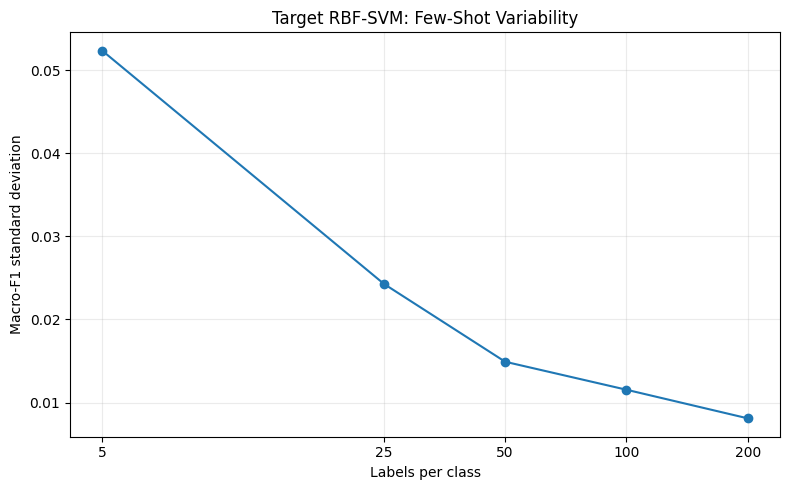

In [91]:
stability = (
    final_method_summary[
        [
            "n_shots",
            "macro_f1_mean",
            "macro_f1_std",
        ]
    ]
    .copy()
)

stability[
    "coefficient_of_variation"
] = (
    stability[
        "macro_f1_std"
    ]
    / stability[
        "macro_f1_mean"
    ]
)

display(
    stability
)

stability.to_csv(
    OUTPUT_DIR
    / "stability_analysis.csv",
    index=False,
)

fig, ax = plt.subplots(
    figsize=(8, 5)
)

ax.plot(
    stability[
        "n_shots"
    ],
    stability[
        "macro_f1_std"
    ],
    marker="o",
)

ax.set_xscale(
    "log",
    base=2,
)

ax.set_xticks(
    OFFICIAL_SHOTS
)

ax.set_xticklabels(
    [
        str(x)
        for x
        in OFFICIAL_SHOTS
    ]
)

ax.set_xlabel(
    "Labels per class"
)

ax.set_ylabel(
    "Macro-F1 standard deviation"
)

ax.set_title(
    f"{FINAL_METHOD}: Few-Shot Variability"
)

ax.grid(
    alpha=0.25,
)

plt.tight_layout()

path = (
    FIGURE_DIR
    / "final_method_variability.png"
)

plt.savefig(
    path,
    dpi=180,
    bbox_inches="tight",
)

plt.show()

## 20. Automated interpretation

This cell prints a concise evidence-based interpretation that can be adapted for the presentation or report.

In [92]:
best_average_row = (
    leaderboard.iloc[
        0
    ]
)

best_25_row = (
    leaderboard
    .sort_values(
        "f1_25",
        ascending=False,
    )
    .iloc[
        0
    ]
)

best_peak_row = (
    leaderboard
    .sort_values(
        "peak_mean_f1",
        ascending=False,
    )
    .iloc[
        0
    ]
)

five_row = (
    final_method_summary[
        final_method_summary[
            "n_shots"
        ]
        == 5
    ]
    .iloc[
        0
    ]
)

twentyfive_row = (
    final_method_summary[
        final_method_summary[
            "n_shots"
        ]
        == 25
    ]
    .iloc[
        0
    ]
)

twohundred_row = (
    final_method_summary[
        final_method_summary[
            "n_shots"
        ]
        == 200
    ]
    .iloc[
        0
    ]
)

print(
    "FINAL INTERPRETATION"
)

print(
    "--------------------"
)

print(
    f"1. The frozen Madrid source model scored "
    f"{MADRID_CV:.4f} Macro-F1 in Madrid but only "
    f"{ZERO_SHOT:.4f} in zero-shot Amsterdam, a drop of "
    f"{DOMAIN_DROP:.4f}. This confirms a substantial cross-city domain shift."
)

print(
    f"2. The strongest transfer method was {FINAL_METHOD}. "
    f"Its average Macro-F1 across the five official label budgets was "
    f"{float(best_average_row['average_f1']):.4f}."
)

print(
    f"3. At the key 25-label-per-class setting, {FINAL_METHOD} reached "
    f"{float(twentyfive_row['macro_f1_mean']):.4f} ± "
    f"{float(twentyfive_row['macro_f1_std']):.4f}."
)

print(
    f"4. Performance rose from "
    f"{float(five_row['macro_f1_mean']):.4f} ± "
    f"{float(five_row['macro_f1_std']):.4f} at 5-shot to "
    f"{float(twohundred_row['macro_f1_mean']):.4f} ± "
    f"{float(twohundred_row['macro_f1_std']):.4f} at 200-shot."
)

print(
    f"5. The 25-shot adapter recovered approximately "
    f"{RECOVERED_25:.1%} of the zero-shot source-to-target performance gap."
)

if (
    spatial_summary
    is not None
):
    spatial_25 = (
        spatial_summary[
            (
                spatial_summary[
                    "method"
                ]
                == FINAL_METHOD
            )
            & (
                spatial_summary[
                    "n_shots"
                ]
                == 25
            )
        ]
    )

    if len(
        spatial_25
    ):
        ordinary = float(
            spatial_25[
                "macro_f1_mean"
            ].iloc[
                0
            ]
        )

        buffered = float(
            spatial_25[
                "spatial_macro_f1_mean"
            ].iloc[
                0
            ]
        )

        print(
            f"6. At 25-shot, spatial buffering changed Macro-F1 from "
            f"{ordinary:.4f} to {buffered:.4f}, a difference of "
            f"{ordinary - buffered:.4f}."
        )

FINAL INTERPRETATION
--------------------
1. The frozen Madrid source model scored 0.6768 Macro-F1 in Madrid but only 0.3943 in zero-shot Amsterdam, a drop of 0.2825. This confirms a substantial cross-city domain shift.
2. The strongest transfer method was Target RBF-SVM. Its average Macro-F1 across the five official label budgets was 0.6098.
3. At the key 25-label-per-class setting, Target RBF-SVM reached 0.5950 ± 0.0243.
4. Performance rose from 0.4481 ± 0.0523 at 5-shot to 0.6998 ± 0.0081 at 200-shot.
5. The 25-shot adapter recovered approximately 71.1% of the zero-shot source-to-target performance gap.
6. At 25-shot, spatial buffering changed Macro-F1 from 0.5950 to 0.5903, a difference of 0.0047.


## 21. Save final analysis summary

The JSON below provides a compact machine-readable record for a README, presentation generator, or reporting script.

In [93]:
analysis_summary = {
    "source_model": (
        source_bundle[
            "model_name"
        ]
    ),
    "final_transfer_method": (
        FINAL_METHOD
    ),
    "madrid_cv_macro_f1": (
        MADRID_CV
    ),
    "amsterdam_zero_shot_macro_f1": (
        ZERO_SHOT
    ),
    "domain_shift_drop": (
        DOMAIN_DROP
    ),
    "best_average_macro_f1": (
        float(
            best_average_row[
                "average_f1"
            ]
        )
    ),
    "best_25_shot_macro_f1": (
        float(
            best_25_row[
                "f1_25"
            ]
        )
    ),
    "best_peak_mean_macro_f1": (
        float(
            best_peak_row[
                "peak_mean_f1"
            ]
        )
    ),
    "final_method_5_shot_mean": (
        float(
            five_row[
                "macro_f1_mean"
            ]
        )
    ),
    "final_method_5_shot_sd": (
        float(
            five_row[
                "macro_f1_std"
            ]
        )
    ),
    "final_method_25_shot_mean": (
        float(
            twentyfive_row[
                "macro_f1_mean"
            ]
        )
    ),
    "final_method_25_shot_sd": (
        float(
            twentyfive_row[
                "macro_f1_std"
            ]
        )
    ),
    "final_method_200_shot_mean": (
        float(
            twohundred_row[
                "macro_f1_mean"
            ]
        )
    ),
    "final_method_200_shot_sd": (
        float(
            twohundred_row[
                "macro_f1_std"
            ]
        )
    ),
    "gap_recovered_25_shot": (
        float(
            RECOVERED_25
        )
    ),
    "gap_recovered_200_shot": (
        float(
            RECOVERED_200
        )
    ),
    "official_shots": (
        OFFICIAL_SHOTS
    ),
    "trials_per_shot": (
        int(
            transfer_summary[
                "trials_per_shot"
            ]
        )
    ),
    "spatial_buffer_diagnostic": (
        bool(
            transfer_summary.get(
                "spatial_buffer_diagnostic",
                False,
            )
        )
    ),
}

with (
    OUTPUT_DIR
    / "final_analysis_summary.json"
).open(
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        analysis_summary,
        f,
        indent=2,
    )

print(
    json.dumps(
        analysis_summary,
        indent=2,
    )
)

{
  "source_model": "RBF SVM",
  "final_transfer_method": "Target RBF-SVM",
  "madrid_cv_macro_f1": 0.676814711557677,
  "amsterdam_zero_shot_macro_f1": 0.3943133335730136,
  "domain_shift_drop": 0.2825013779846634,
  "best_average_macro_f1": 0.6098383500178277,
  "best_25_shot_macro_f1": 0.5950441600349284,
  "best_peak_mean_macro_f1": 0.6997726044345557,
  "final_method_5_shot_mean": 0.448070755184559,
  "final_method_5_shot_sd": 0.0523206940317502,
  "final_method_25_shot_mean": 0.5950441600349284,
  "final_method_25_shot_sd": 0.0242849743361659,
  "final_method_200_shot_mean": 0.6997726044345557,
  "final_method_200_shot_sd": 0.0081144272884488,
  "gap_recovered_25_shot": 0.7105481321680923,
  "gap_recovered_200_shot": 1.0812664810368642,
  "official_shots": [
    5,
    25,
    50,
    100,
    200
  ],
  "trials_per_shot": 30,
  "spatial_buffer_diagnostic": true
}


## 22. Final output checklist

After running this notebook, the `track_d` folder should contain the final evidence needed for a presentation, report, README, or submission.

Key files include:

```text
track_d/
├── headline_results.csv
├── final_results_table.csv
├── final_per_class_results.csv
├── final_leaderboard.csv
├── stability_analysis.csv
├── zero_shot_confusion_matrix.csv
├── target_svm_25_shot_confusion_matrix.csv
├── target_svm_200_shot_confusion_matrix.csv
├── final_analysis_summary.json
└── figures/
    ├── amsterdam_class_distribution.png
    ├── domain_shift_and_recovery.png
    ├── f1_vs_shots.png
    ├── boxplot_25_shot.png
    ├── final_method_boxplot_by_shot.png
    ├── histogram_final_method_25_shot.png
    ├── final_method_per_class_f1.png
    ├── spatial_buffer_comparison.png
    ├── zero_shot_confusion_matrix.png
    ├── target_svm_25_shot_confusion_matrix.png
    ├── target_svm_200_shot_confusion_matrix.png
    └── final_method_variability.png
```

In [94]:
print(
    "=" * 72
)

print(
    "TRACK D COMPLETE"
)

print(
    "=" * 72
)

print(
    "Source model:",
    source_bundle[
        "model_name"
    ],
)

print(
    "Final transfer method:",
    FINAL_METHOD,
)

print(
    "Madrid CV:",
    f"{MADRID_CV:.4f}",
)

print(
    "Amsterdam zero-shot:",
    f"{ZERO_SHOT:.4f}",
)

print(
    "25-shot:",
    f"{F1_25:.4f}",
)

print(
    "200-shot:",
    f"{F1_200:.4f}",
)

print(
    "\nSaved figures:"
)

for path in sorted(
    FIGURE_DIR.iterdir()
):
    if path.is_file():
        print(
            " -",
            path.name,
        )

print(
    "\nTrack D output folder:"
)

print(
    OUTPUT_DIR
)

TRACK D COMPLETE
Source model: RBF SVM
Final transfer method: Target RBF-SVM
Madrid CV: 0.6768
Amsterdam zero-shot: 0.3943
25-shot: 0.5950
200-shot: 0.6998

Saved figures:
 - amsterdam_class_distribution.png
 - boxplot_25_shot.png
 - domain_shift_and_recovery.png
 - f1_vs_shots.png
 - final_method_boxplot_by_shot.png
 - final_method_per_class_f1.png
 - final_method_variability.png
 - histogram_final_method_25_shot.png
 - spatial_buffer_comparison.png
 - target_svm_200_shot_confusion_matrix.png
 - target_svm_25_shot_confusion_matrix.png
 - zero_shot_confusion_matrix.png

Track D output folder:
/kaggle/working/track_d
